In [10]:
import os
import numpy as np
import torch
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from scipy.stats import multinomial
from src.model_toy_data import Model
import seaborn as sns
mpl.rcParams['text.usetex'] = True
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "Times New Roman"
fontsize=27

# Set random seed for reproducibility
seed = 1
np.random.seed(seed)
torch.manual_seed(seed)

In [11]:
# Define the dataset parameters
k = 4 # Length of k-mers
class_num = 5 # Number of clusters
sequence_length = 100 # Number of k-mers, (i.e. number of trials of the multinomial distribution)
class_sizes = [25]*class_num # Number of sequences per cluster
p_intra = 1. # Probability of a sequence belonging to a single cluster
epsilon = 1e-2 # Small value to avoid zero probabilities in Dirichlet prior
multi_class_seq_num = 5 # Number of sequences belonging to multiple clusters

# Define the number of k-mers and total sequences
kmers_num = 4**k
sequence_num = sum(class_sizes)


# Define the parameters of the Multinomial distribution for each cluster
# Each cluster has higher concentration on its own dimensions
probs = np.zeros(shape=(class_num, kmers_num))
dim_count_per_class = kmers_num // class_num
for class_idx in range(class_num):

    # Set higher concentration for the dimensions corresponding to the current class
    probs[class_idx, class_idx*dim_count_per_class:(class_idx+1)*dim_count_per_class] = 1
    # Add small epsilon to all dimensions to avoid zero probabilities
    probs[class_idx, :] += epsilon

    # Last class takes the rest
    if class_idx == class_num - 1:
        probs[class_idx, (class_idx+1)*dim_count_per_class:] = 1
# Normalize to get valid probability distributions
probs = probs / probs.sum(axis=1, keepdims=True)


# Now sample the k-mer counts from the multinomial distribution for each cluster
# The first cluster_sizes[0] points come from cluster 0, next cluster_sizes[1] points come from cluster 1, and so on.
normalized_kmer_counts = np.zeros(shape=(sequence_num, kmers_num), dtype=float)
start = 0
for class_idx in range(class_num):
    end = start + class_sizes[class_idx]
    # Sample k-mer counts for the current class
    normalized_kmer_counts[start:end, :] = multinomial.rvs(sequence_length, probs[class_idx, :], size=class_sizes[class_idx] )
    start = end
normalized_kmer_counts = normalized_kmer_counts / normalized_kmer_counts.sum(axis=1, keepdims=True)  # Normalize each row to sum to 1

# Construct positive pairs by taking two samples from the same cluster
pairs = []
for class_idx in range(class_num):
    start = sum(class_sizes[:class_idx])
    end = start + class_sizes[class_idx]
    for i in range(start, end):
        for j in range(i + 1, end):
            if np.random.rand() <= p_intra:  # Only add the pair with probability p_intra
                pairs.append([normalized_kmer_counts[i], normalized_kmer_counts[j]])


# Construct 'multi_class_seq_num' kmers sequences belonging to multiple clusters
multi_class_seq_class_indices = np.sort(np.random.choice(class_num, size=3, replace=False))
print(multi_class_seq_class_indices)
# Sample their k-mer counts by summing the counts from the selected clusters
new_kmer_counts = np.zeros(shape=(multi_class_seq_num, kmers_num), dtype=float)
for class_idx in multi_class_seq_class_indices:
    new_kmer_counts += multinomial.rvs(sequence_length, probs[class_idx, :], size=multi_class_seq_num ).astype(float)
new_kmer_counts = new_kmer_counts / new_kmer_counts.sum(axis=1, keepdims=True)

# Add them to the normalized_kmer_counts
normalized_kmer_counts = np.vstack([normalized_kmer_counts, new_kmer_counts])

# Construct pairs for these new kmers sequences
for c in multi_class_seq_class_indices:
    start = sum(class_sizes[:c])
    end = start + class_sizes[c]
    for i in range(start, end):
        for j in range(multi_class_seq_num):
            if np.random.rand() <= p_intra:
                pairs.append([normalized_kmer_counts[i], normalized_kmer_counts[-1-j]])


[0 1 3]


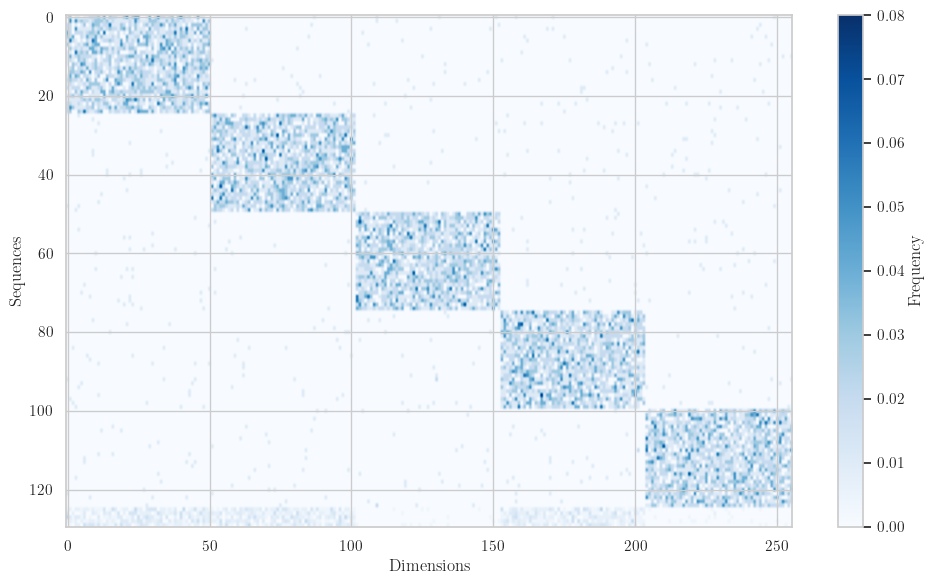

In [12]:
# Define output directory
output_dir = os.path.join(os.getcwd(), '..', 'notebooks', 'kmers_toy_example')
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# Plot the sampled probabilities
plt.figure(figsize=(10, 6))
plt.imshow(normalized_kmer_counts, aspect='auto', cmap='Blues')
plt.colorbar(label='Frequency')
# plt.title('K-mer Frequency Distribution Across Sequences')
plt.xlabel('Dimensions')
plt.ylabel('Sequences')
# plt.show()
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'kmers_frequency_distribution.png'))

# Write the pairs to a CSV file
output_file = os.path.join(output_dir, 'kmer_toy_example_data.csv')
with open(output_file, 'w') as f:
    for left, right in pairs:
        left = ' '.join(map(str, left))
        right = ' '.join(map(str, right))
        f.write(f"{left},{right}\n")

In [19]:
# Train the model

# Define model parameters
K = 4
out_dim = 2
neg_sample_per_pos = 2 #200
max_seq_num = 0
epoch_num = 50 #20
lr = 0.01
batch_size = 200
save_every = 0
device = "mps"
strategy = "together"

# Define file paths
input_file_path = os.path.join(output_dir, 'kmer_toy_example_data.csv')
checkpoint_model_file_path = os.path.join(output_dir, 'kmer_toy_example_mean.model')
model_file_path = os.path.join(output_dir, 'kmer_toy_example.model')

# Define the command to train the model
cmd=f"python {os.path.join(os.getcwd(), '..', 'src','model_toy_data.py')}  --input {input_file_path} --output {model_file_path}"
cmd+=f" --k {k} --out_dim {out_dim} --neg_sample_per_pos {neg_sample_per_pos} --max_seq_num {max_seq_num}"
cmd+=f" --epoch {epoch_num} --lr {lr} --batch_size {batch_size} --save_every {save_every} --distributed 0"
cmd+=f" --device {device} --loss_name mahalanobis --seed {seed} --strategy {strategy}"
# Run the command
os.system(f"{cmd}")



+ Information
	- k value: 4
	- Loss name: mahalanobis
	- Epoch number: 15
	- Batch size: 200
	- Learning rate: 0.01
	- Output dimension: 2
	- Negative sample per positive pair: 2
	- Maximum number of sequence pairs to use: 0
	- Learning starting strategy: together
	- No distributed training
	- Device: mps
	- Number of data loading workers: 2
	- Seed value: 1
	- Output model name: kmer_toy_example.model
+ Reading the data file.
	- File path: /Users/abdulkadircelikkanat/Downloads/kum/notebooks/../notebooks/kmers_toy_example/kmer_toy_example_data.csv
	- Completed in 0.11 seconds.
	- The input file contains: 1875 sequence pairs.
	- For training, 0 sequence pairs will be used.
+ Constructing the indices for positive and negative sample pairs
	- Completed in 0.00 seconds.
	- Training dataset contains 1875 positive pairs.
	- Training dataset contains 3750 negative pairs.
+ Training started.
	- Epoch: 1/15 - Loss: 0.6440595429519127 (2.20 secs)
	- Epoch: 2/15 - Loss: 0.4460498546731883 (1.31 s

0

In [20]:
# # Define the command to train the model for variance terms
# cmd=f"python {os.path.join(os.getcwd(), '..', 'src','model_toy_data.py')}  --input {input_file_path} --output {model_file_path}"
# cmd+=f" --k {k} --out_dim {out_dim} --neg_sample_per_pos {neg_sample_per_pos} --max_seq_num {max_seq_num}"
# cmd+=f" --epoch 150 --lr {lr} --batch_size {batch_size} --save_every {save_every} --distributed 0"
# cmd+=f" --device {device} --loss_name mahalanobis --seed {seed} --strategy var_only --checkpoint {checkpoint_model_file_path}"
# # Run the command
# os.system(f"{cmd}")

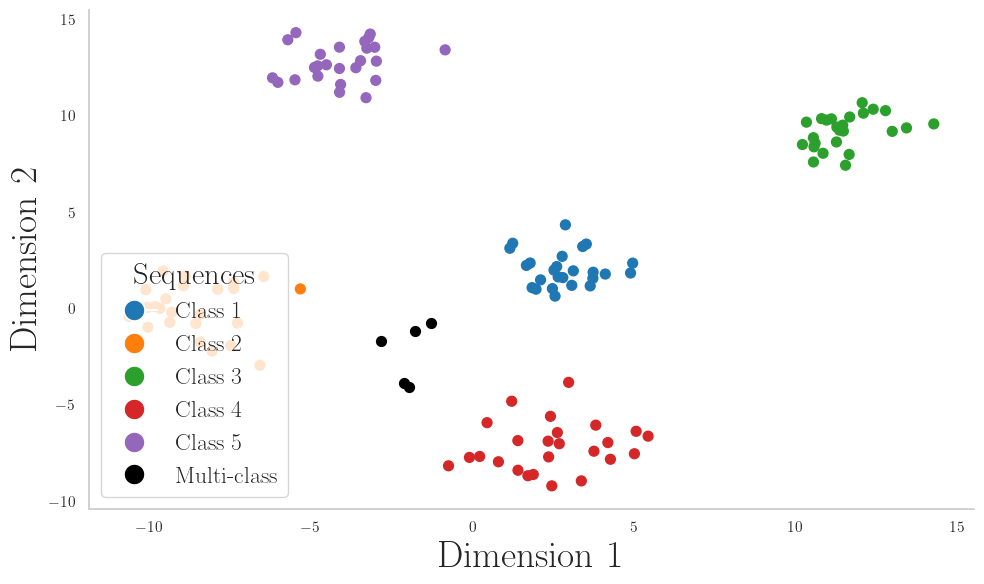

In [21]:
# Load the model
kwargs, model_state_dict = torch.load(model_file_path, map_location=torch.device("cpu"))
model = Model(**kwargs)
model.load_state_dict(model_state_dict)
embs, covs = model.seq2emb(normalized_kmer_counts)


plt.figure(figsize=(10,6))
# plt.title('2D Embeddings of k-mer sequences')
colors = mpl.colormaps['tab10']  # Get a colormap with K distinct colors
class_indices = np.array([i // (sequence_num // class_num) for i in range(sequence_num)])
point_colors = colors(class_indices)
plt.scatter(embs[:sequence_num, 0], embs[:sequence_num, 1], c=point_colors, s=50, alpha=1.)
for i in range(multi_class_seq_num):
    plt.scatter(embs[sequence_num + i, 0], embs[sequence_num + i, 1], c='black', marker='o', s=50, label=f'New Seq {i+1}')

plt.xlabel('Dimension 1', fontsize=fontsize)
plt.ylabel('Dimension 2', fontsize=fontsize)
plt.grid(False)
# Add legend for classes
handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=colors(i), markersize=15, label=f'Class {i+1}') for i in range(class_num)]
handles.append(plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='black', markersize=15, label='Multi-class'))
plt.legend(handles=handles, title='Sequences', loc='lower left', fontsize=fontsize-10, title_fontsize=fontsize-5)
# Remove the numbers on the axes
# plt.xticks([])
# plt.yticks([])
# Remove the box around the plot
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
# plt.gca().spines['left'].set_visible(False)
# plt.gca().spines['bottom'].set_visible(False)
# Set equal aspect ratio
# plt.show()
#
# Remove the blank space around the plot
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'embedding_space.png'))



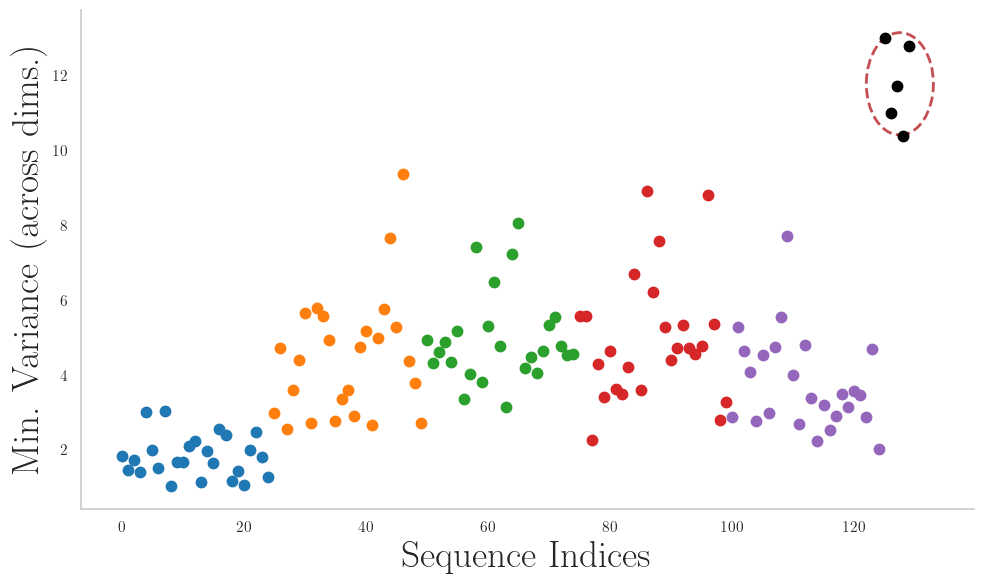

In [22]:
# Plot the distribution of the sequences
plt.figure(figsize=(10, 6))
selected_cov_values = covs[:, :].min(axis=-1)
# plt.plot(range(len(selected_cov_values)), selected_cov_values, '.', label='Cov Dimension 1')
for i in range(multi_class_seq_num):
    start = sum(class_sizes[:i])
    end = start + class_sizes[i]
    plt.plot(range(start, end), selected_cov_values[start:end], '.', label=f'Class {i+1}', markersize=15, color=colors(i))
plt.plot(
    range(sequence_num, sequence_num+multi_class_seq_num), selected_cov_values[sequence_num:], '.',
    markersize=15, color='black', label='Multi-class'
)
# Draw an ellipse
center_x = (sequence_num + multi_class_seq_num/2)
center_y = selected_cov_values[sequence_num:].mean()
# Width is the distance between the first and last of the last 5 points
width = multi_class_seq_num + 6
# Height is the distance between the max and min of the last 5 points
height = selected_cov_values[sequence_num:].max() - selected_cov_values[sequence_num:].min() + 0.1
ellipse = Ellipse(
    (center_x,center_y), width=width, height=height, angle=0,
    edgecolor='r', facecolor='none', linestyle='--', linewidth=2, label='Multi-class Sequences'
)
plt.gca().add_patch(ellipse)
plt.grid(False)
# Remove the top and right spines
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.xlabel('Sequence Indices', fontsize=fontsize)
plt.ylabel('Min. Variance (across dims.)', fontsize=fontsize)
# plt.title('Covariance of K-mer Sequences')
# plt.show()
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'variance_distribution.png'))

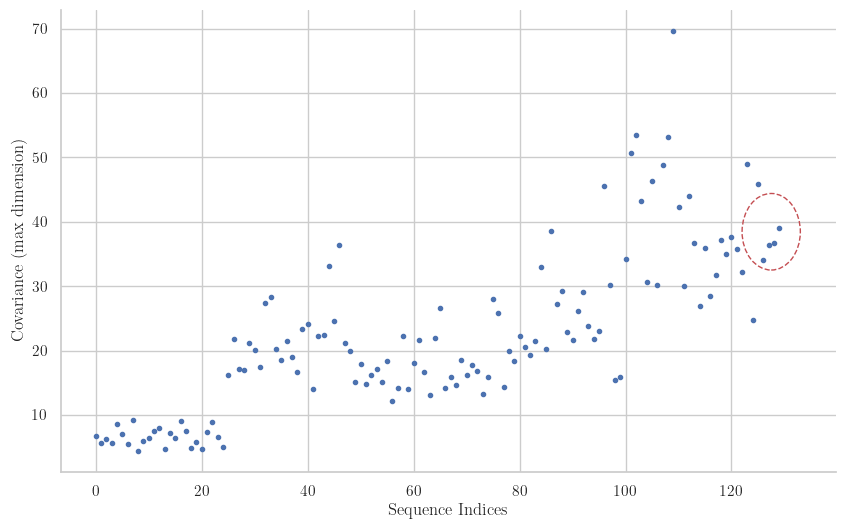

In [23]:
# Plot the distribution of the sequences
plt.figure(figsize=(10, 6))
selected_cov_values = covs[:, :].max(axis=-1)
plt.plot(range(len(selected_cov_values)), selected_cov_values, '.', label='Cov Dimension 1')
# Draw an ellipse
center_x = (sequence_num + multi_class_seq_num/2)
center_y = selected_cov_values[sequence_num:].mean()
# Width is the distance between the first and last of the last 5 points
width = multi_class_seq_num + 6
# Height is the distance between the max and min of the last 5 points
height = selected_cov_values[sequence_num:].max() - selected_cov_values[sequence_num:].min() + 0.1
ellipse = Ellipse((center_x,center_y), width=width, height=height, angle=0, edgecolor='r', facecolor='none', linestyle='--', label='Multi-class Sequences')
plt.gca().add_patch(ellipse)

# Remove the top and right spines
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.xlabel('Sequence Indices')
plt.ylabel('Covariance (max dimension)')
# plt.title('Covariance of K-mer Sequences')
plt.show()

In [24]:
a = np.zeros(shape=(1, 4**4))
a[0, 1] = 1
a[0, :] = 1e-5
a = a / a.sum()

xembs, xcovs = model.seq2emb(a)

print(xembs, xcovs)

[[0.722475  3.5597436]] [[21.259558  4.377502]]
